## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline

In [6]:
df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [7]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


### Part 1: Analyzing Best-Seller Trends Across Product Categories

Objective: Understand the relationship between product categories and their best-seller status.

In [8]:
# Crosstab Analysis
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [9]:
# Hint
best_seller_prop = crosstab_result[True]/crosstab_result.sum(axis=1)
best_seller_prop = best_seller_prop.sort_values(ascending=False)

best_seller_prop

category
Grocery                             0.058135
Smart Home Security & Lighting      0.057692
Health & Personal Care              0.057686
Mobile Phone Accessories            0.042471
Power & Hand Tools                  0.035339
                                      ...   
CD, Disc & Tape Players             0.000000
General Music-Making Accessories    0.000000
Snowboard Boots                     0.000000
Boxes & Organisers                  0.000000
eBook Readers & Accessories         0.000000
Length: 296, dtype: float64

- Are there categories where being a best-seller is more prevalent?
  
Yes, grocery has the highest proportion of best-sellers, with around 5.81% of its products being best-sellers.

In [14]:
# Statistical Tests

from scipy.stats import chi2_contingency

chi2_statistic, chi2_p_value, _, expected_freq = chi2_contingency(crosstab_result)
print("Chi-square:", chi2_statistic)
print("p-value:", chi2_p_value)

Chi-square: 36540.20270061387
p-value: 0.0


as p-value < 0.05 then reject H₀. Category and best-seller status are not independent.

In [15]:
from scipy.stats.contingency import association
association(crosstab_result, method="cramer")


0.1222829439760564

Carmers's V indicates a weak association between Best-Seller status and category.

<Axes: xlabel='category'>

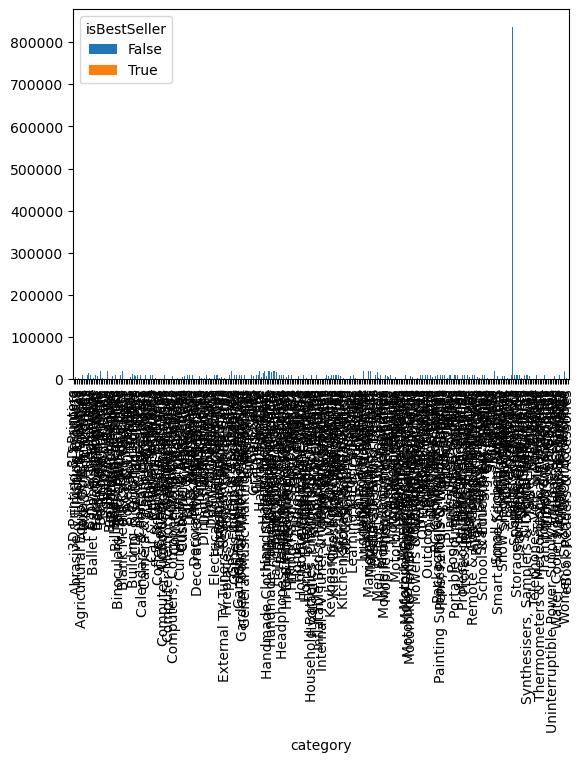

In [18]:
# Visualizations
crosstab_result.plot(kind="bar", stacked=True)

<Axes: xlabel='category'>

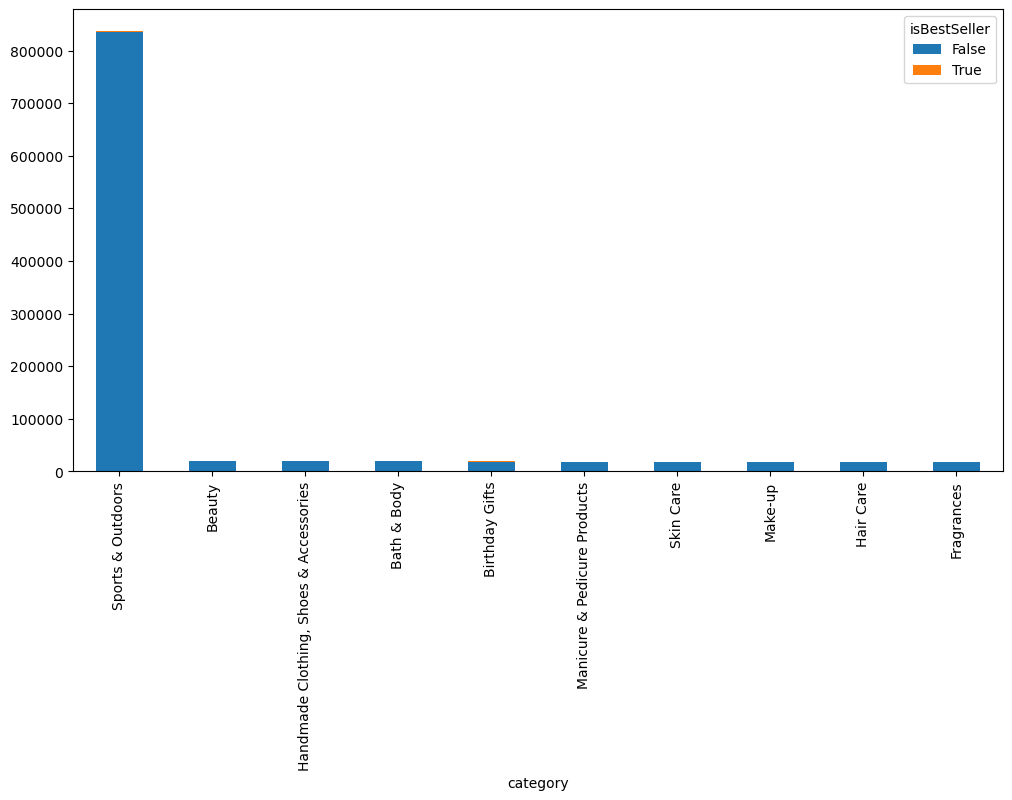

In [19]:
top_10_categories = df['category'].value_counts().head(10).index

crosstab_top10 = crosstab_result.loc[top_10_categories]

crosstab_top10.plot(kind='bar', stacked=True, figsize=(12, 6))

### Part  2: Exploring Product Prices and Ratings Across Categories and Brands

Objective: Investigate how different product categories influence product prices.

In [20]:
# Preliminary Step: Remove outliers in product prices.
def tukeys_test_outliers(data):
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    outliers = data[(data < lower_bound) | (data > upper_bound)]

    return outliers

In [21]:
product_prices = df['price']  
outliers = tukeys_test_outliers(product_prices)
print(outliers)

10         139.00
19         164.99
25         149.99
28         289.00
31         199.99
            ...  
2443619    166.99
2443627    152.58
2443638    108.77
2443641    166.99
2443643    158.99
Name: price, Length: 327688, dtype: float64


In [22]:
df_no_outliers = df.drop(outliers.index)

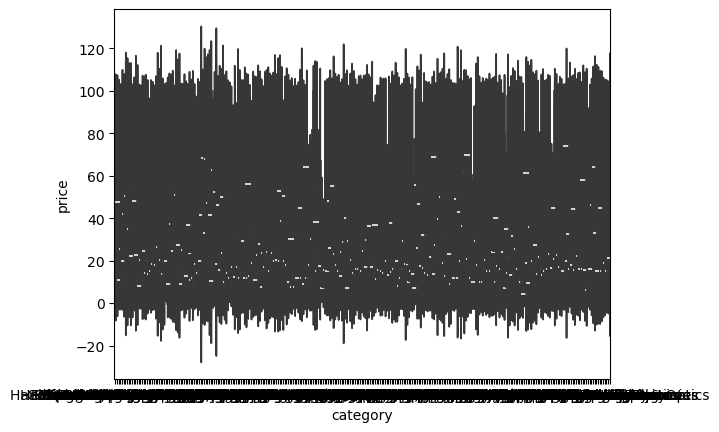

In [26]:
# Violin Plots
sns.violinplot(data=df_no_outliers, x='category', y='price', palette="coolwarm", hue='category', legend=False)

In [28]:
top_20_categories = df_no_outliers['category'].value_counts().head(20).index
df_top20 = df_no_outliers[df_no_outliers['category'].isin(top_20_categories)]

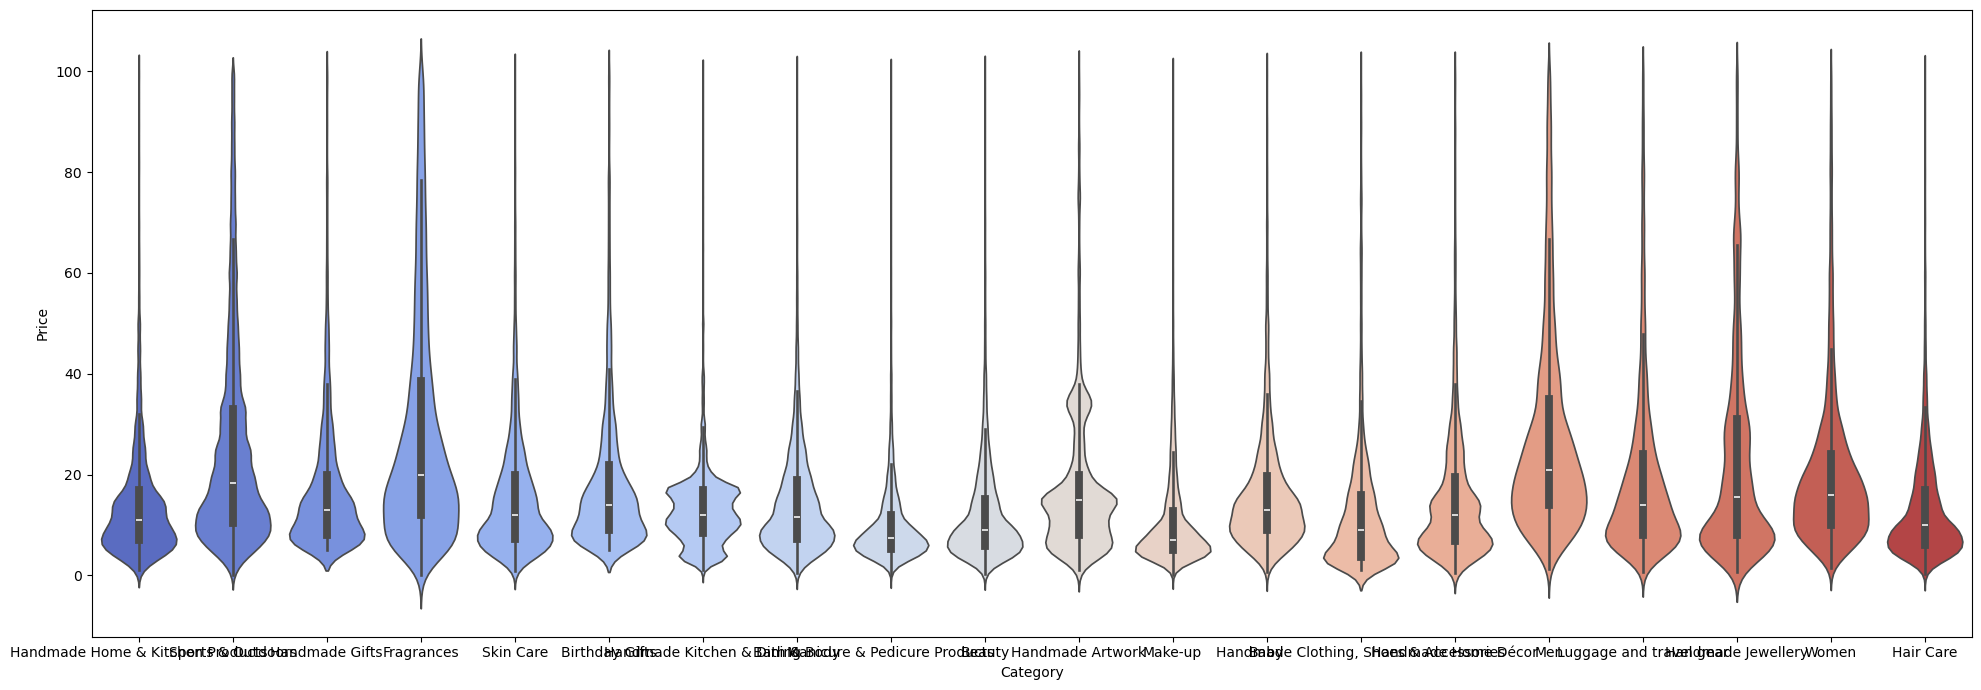

In [34]:
plt.figure(figsize=(20, 7))
sns.violinplot(data=df_top20, x='category', y='price', palette="coolwarm", hue='category', legend=False)

#plt.xticks(rotation=45, ha='right')
plt.xlabel('Category')
plt.ylabel('Price')
plt.tight_layout()
plt.show()

In [35]:
median_prices = df_no_outliers.groupby('category')['price'].median().sort_values(ascending=False)
median_prices.head()

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

- Which product category tends to have the highest median price? Don't filter here by top categories.
  
Desktop PCs have the highest median price, at 74.00

<Axes: xlabel='category', ylabel='price'>

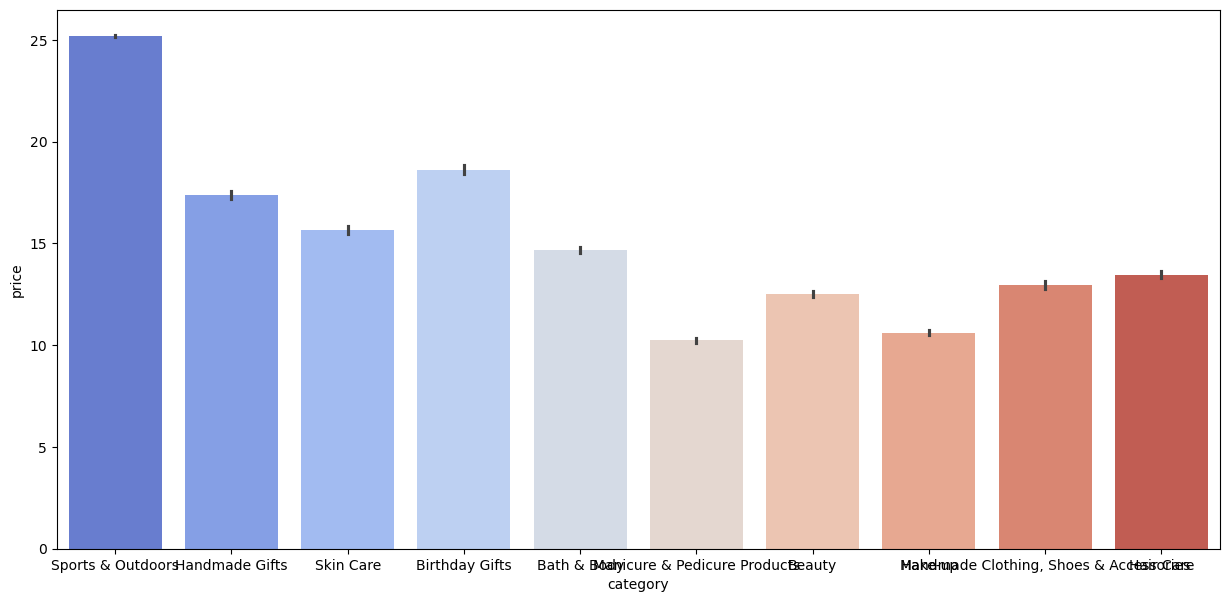

In [39]:
# Bar Charts:
top_10_categories = df_no_outliers['category'].value_counts().head(10).index
df_top10 = df_no_outliers[df_no_outliers['category'].isin(top_10_categories)]

plt.figure(figsize=(15, 7))
sns.barplot(data=df_top10, x='category', y='price', palette="coolwarm", hue='category', legend=False)

In [40]:
mean_price_by_category = df_no_outliers.groupby('category')['price'].mean().sort_values(ascending=False)
mean_price_by_category.head()

category
Motherboards      68.772432
Boxing Shoes      67.417803
Desktop PCs       66.915562
Tablets           66.552971
Graphics Cards    65.103509
Name: price, dtype: float64

- Which product category commands the highest average price? Don't filter here by top categories.

Motherboards commands the highest average price with 68.77

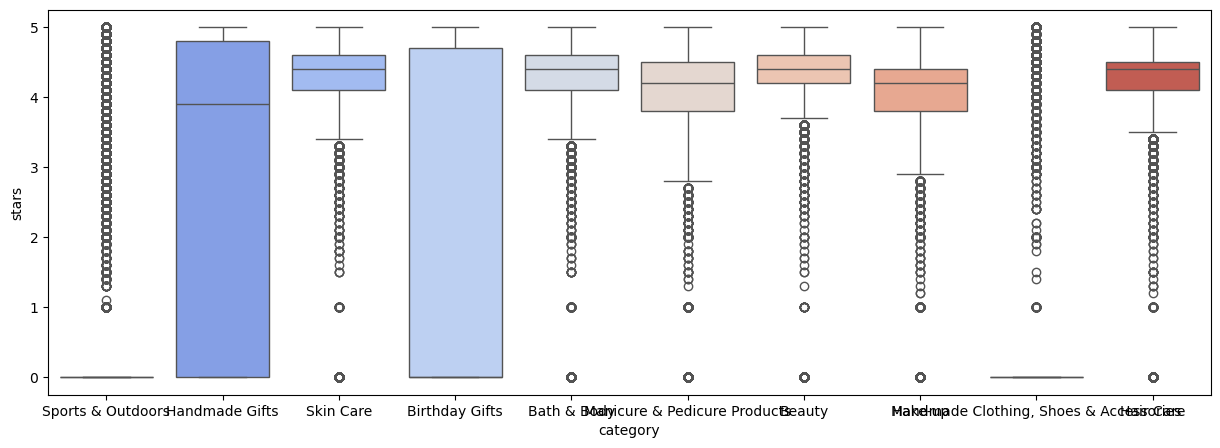

In [43]:
# Box Plots:
plt.figure(figsize=(15, 5))
sns.boxplot(data=df_top10, x='category', y='stars', palette="coolwarm", hue='category', legend=False)

In [44]:
median_rating = df_no_outliers.groupby('category')['stars'].median().sort_values(ascending=False)
median_rating.head()

category
Computer Memory                 4.7
Building & Construction Toys    4.6
Office Paper Products           4.6
Luxury Food & Drink             4.6
Kids' Play Figures              4.6
Name: stars, dtype: float64

- Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

Computer Memory has the highest median rating with 4.7 stars

### Part 3: Investigating the Interplay Between Product Prices and Ratings

Objective: Analyze how product ratings (stars) correlate with product prices.

In [47]:
# Correlation Coefficients:
correlation = df['price'].corr(df['stars'])
correlation

np.float64(-0.1249067326214861)

In [48]:
correlation_no_outliers = df_no_outliers['price'].corr(df_no_outliers['stars'])
correlation_no_outliers

np.float64(-0.0776729987818137)

- Is there a significant correlation between product price and its rating?

There is a very weak negative correlation between product price and rating.

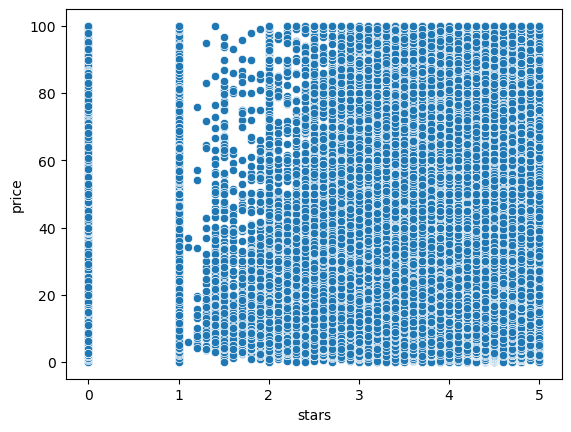

In [49]:
# Visualizations
sns.scatterplot(data=df_no_outliers, x='stars', y='price');

- What patterns can you observe?

There is no clear relationship between product ratings and prices.

In [50]:
correlation_matrix = df_no_outliers[['price', 'stars', 'reviews', 'boughtInLastMonth']].corr()
correlation_matrix

,price,stars,reviews,boughtInLastMonth
price,1.000000,-0.077673,-0.008498,-0.059051
stars,-0.077673,1.000000,0.083920,0.113994
reviews,-0.008498,0.083920,1.000000,0.105624
boughtInLastMonth,-0.059051,0.113994,0.105624,1.000000


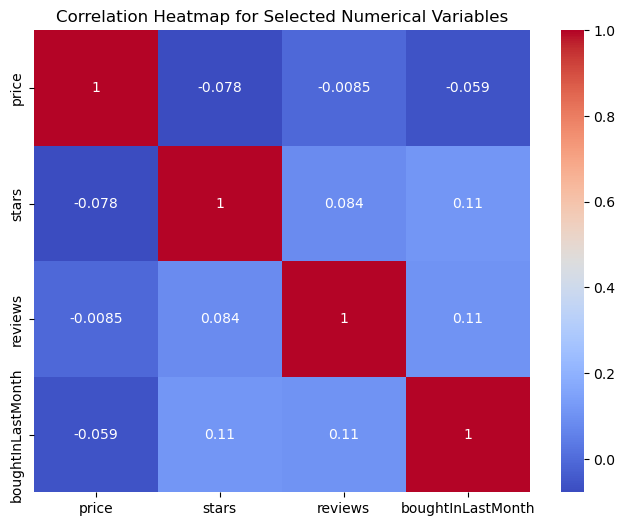

In [53]:
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

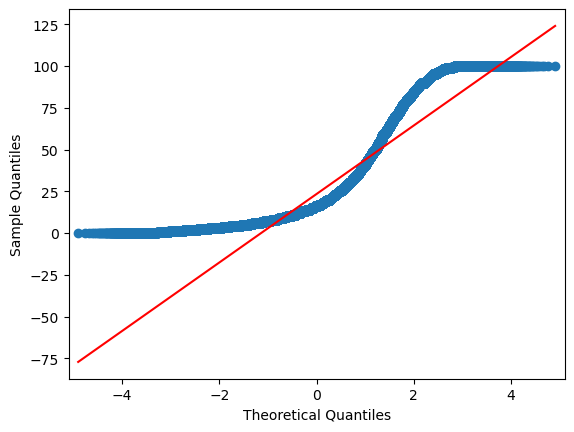

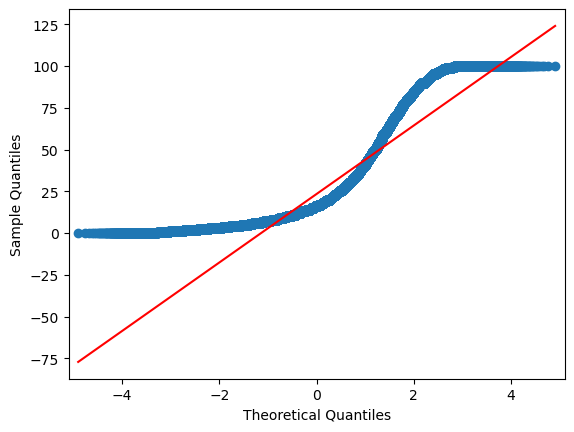

In [55]:
import statsmodels.api as sm
sm.qqplot(df_no_outliers['price'], line='s')

The product prices do not follow a normal distribution, as the points in the QQ plot deviate substantially from the reference line.